# 01 · EDA del dataset municipal curated

Auditoría inicial del Parquet integrado: estructura, cobertura, periodos, distribuciones y valores extremos. Este notebook no modifica los datos de entrada.

In [23]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Mostraremos hasta 150 columnas y 150 filas
pd.set_option('display.max_columns', 150)
pd.set_option('display.max_rows', 150)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'curated' / 'municipios.parquet'
REPORTS_DIR = ROOT / 'outputs' / 'reports'
FIGURES_DIR = ROOT / 'outputs' / 'figures'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f'No existe el dataset curated: {DATA_PATH}')

# Leemos el dataset de municipios
df = pd.read_parquet(DATA_PATH)

# Mostramos el número de filas y columnas del dataset
print(f'Filas: {len(df)} | Columnas: {df.shape[1]}')
df.head()

Filas: 8132 | Columnas: 114


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,codigo_provincia,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,inmuebles_urbanos_catastro_2021,valor_catastral_total_eur_catastro_2021,valor_catastral_suelo_eur_catastro_2021,superficie_urbana_m2_catastro_2021,parcelas_urbanas_catastro_2021,inmuebles_residenciales_catastro_2021,valor_catastral_residencial_eur_catastro_2021,valor_catastral_suelo_eur_m2_catastro_2021,valor_catastral_residencial_medio_eur_catastro_2021,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_trans

In [24]:
# Principales estadísticos descriptivos del dataset
df.describe()

,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,inmuebles_urbanos_catastro_2021,valor_catastral_total_eur_catastro_2021,valor_catastral_suelo_eur_catastro_2021,superficie_urbana_m2_catastro_2021,parcelas_urbanas_catastro_2021,inmuebles_residenciales_catastro_2021,valor_catastral_residencial_eur_catastro_2021,valor_catastral_suelo_eur_m2_catastro_2021,valor_catastral_residencial_medio_eur_catastro_2021,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transa

## Integridad de las claves

In [25]:
# Comprobamos la integridad del dataset (no debe haber municipios duplicados, nulos o códigos repetidos)
integridad = pd.Series({
    'filas': len(df),
    'municipios_distintos': df['codigo_ine'].nunique(dropna=True),
    'codigos_duplicados': df.duplicated('codigo_ine').sum(),
    'codigos_nulos': df['codigo_ine'].isna().sum(),
    'municipios_nulos': df['municipio'].isna().sum(),
    'provincias_nulas': df['provincia'].isna().sum(),
})
display(integridad.to_frame('valores'))

,valores
filas,8132
municipios_distintos,8132
codigos_duplicados,0
codigos_nulos,0
municipios_nulos,0
provincias_nulas,0


## Cobertura y valores nulos

In [26]:
nulos = (
    pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'porcentaje_nulos': df.isna().mean().mul(100).round(2),
        'valores_distintos': df.nunique(dropna=True),
    })
    .sort_values(['porcentaje_nulos', 'nulos'], ascending=False)
)
nulos.to_csv(REPORTS_DIR / 'eda_nulos.csv', encoding='utf-8', index_label='variable')
display(nulos.query('nulos > 0'))

,tipo,nulos,porcentaje_nulos,valores_distintos
total_infracciones,Int64,7705,94.75,400
variacion_alquiler_precio_colectiva_mediana_3_anios,Float64,5886,72.38,1269
variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,Float64,5886,72.38,1504
diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,Float64,5886,72.38,1044
diferencia_alquiler_superficie_colectiva_mediana_3_anios,Float64,5886,72.38,116
diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,Float64,5886,72.38,283
variacion_alquiler_precio_colectiva_mediana_1_anio,Float64,5741,70.60,1045
variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,Float64,5741,70.60,1289
diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,Float64,5741,70.60,898
diferencia_alquiler_superficie_colectiva_mediana_1_anio,Float64,5741,70.60,105


No se tendrán en cuenta las infracciones por municipio por la ausencia de valores en municipios de menos de 20.000 habitantes.

In [27]:
variables_cobertura = {
    'edad': 'edad_media_2025',
    'renta': 'renta_neta_media_persona_eur',
    'catastro': 'inmuebles_residenciales',
    'paro': 'paro_por_1000_habitantes',
    'viviendas': 'viviendas_totales',
    'alquiler_colectiva': 'alquiler_precio_colectiva_mediana',
    'alquiler_unifamiliar': 'alquiler_precio_unifamiliar_mediana',
    'criminalidad': 'total_infracciones',
}
cobertura = pd.DataFrame([
    {
        'fuente': fuente,
        'municipios': int(df[columna].notna().sum()),
        'cobertura_pct': round(df[columna].notna().mean() * 100, 2),
    }
    for fuente, columna in variables_cobertura.items()
]).sort_values('cobertura_pct', ascending=False)
display(cobertura)

,fuente,municipios,cobertura_pct
0,edad,8132,100.00
1,renta,8059,99.10
2,catastro,7606,93.53
3,paro,7430,91.37
4,viviendas,3139,38.60
6,alquiler_unifamiliar,3020,37.14
5,alquiler_colectiva,2555,31.42
7,criminalidad,427,5.25


### Relación entre los nulos de Catastro y la provincia

Se utiliza `inmuebles_residenciales` como indicador de cobertura del Catastro, de forma coherente con la tabla anterior. Se calcula para cada provincia el número y el porcentaje de municipios sin información catastral. Esto permite distinguir ausencias territoriales estructurales de valores nulos aislados.

,municipios,municipios_sin_catastro,porcentaje_sin_catastro
provincia,,,
Navarra,272,272,100.00
Bizkaia,113,113,100.00
Gipuzkoa,88,88,100.00
Araba/Álava,51,51,100.00
Pontevedra,61,1,1.64
A Coruña,93,1,1.08
Alacant/Alicante,141,0,0.00
Albacete,87,0,0.00
Almería,103,0,0.00


Municipios sin Catastro: 526
Provincias con algún municipio sin Catastro: 6


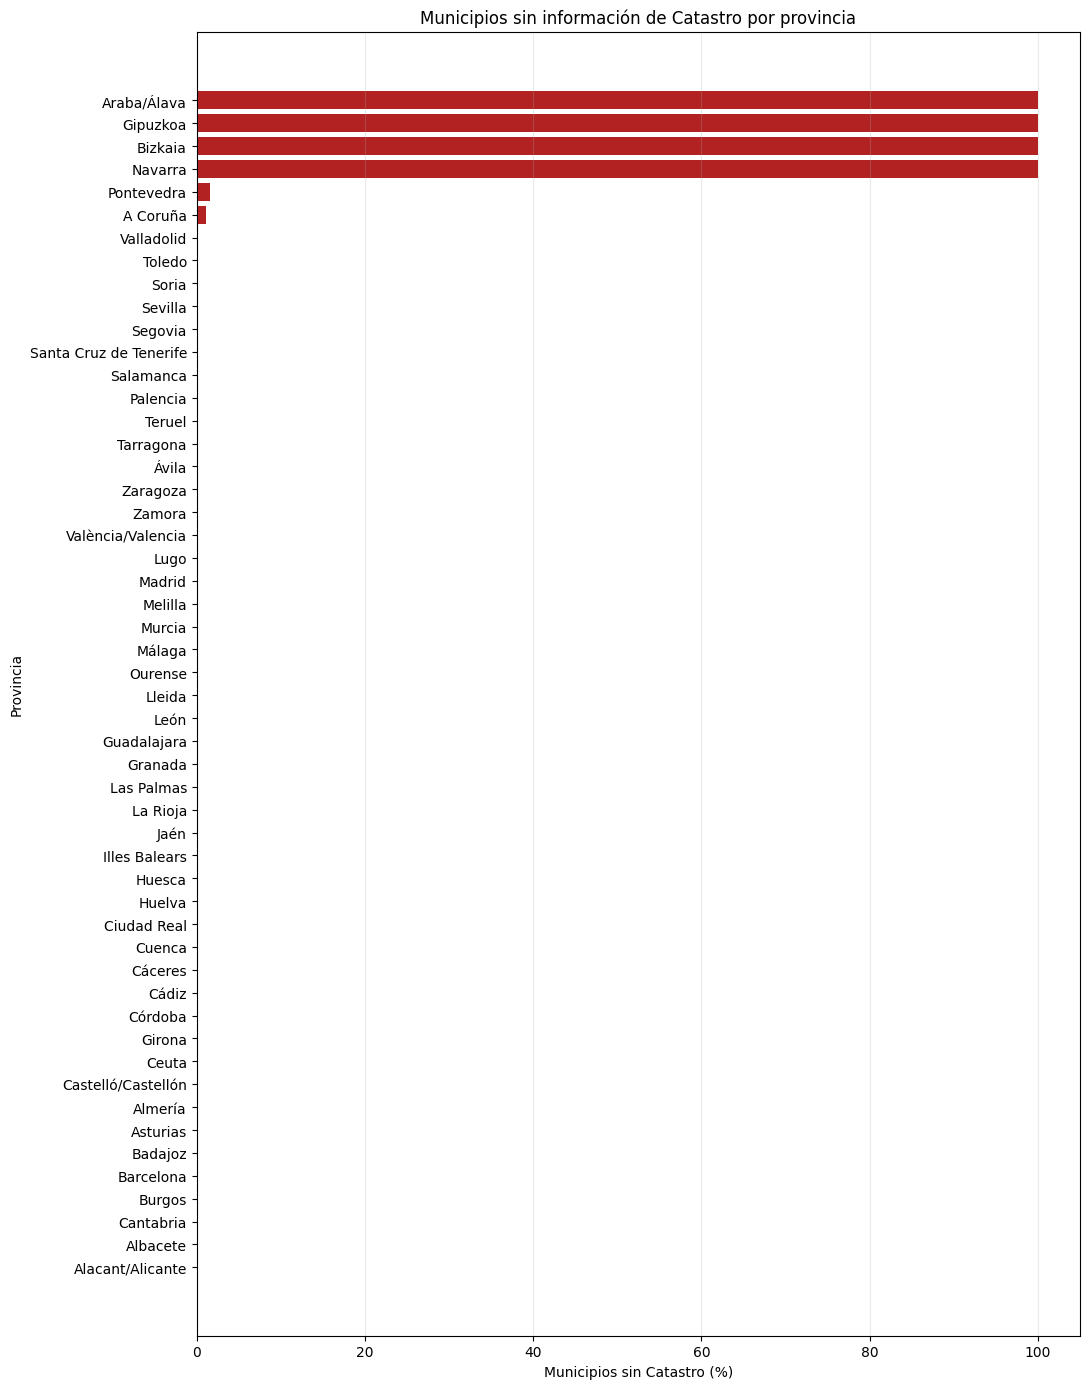

In [39]:
catastro_por_provincia = (
    df.assign(catastro_nulo=df['inmuebles_residenciales'].isna())
    .groupby('provincia', dropna=False)
    .agg(
        municipios=('codigo_ine', 'size'),
        municipios_sin_catastro=('catastro_nulo', 'sum'),
    )
    .assign(
        porcentaje_sin_catastro=lambda x: (
            x['municipios_sin_catastro'].div(x['municipios']).mul(100).round(2)
        )
    )
    .sort_values(
        ['porcentaje_sin_catastro', 'municipios_sin_catastro'],
        ascending=False,
    )
)

display(catastro_por_provincia)

provincias_con_nulos_catastro = catastro_por_provincia.query(
    'municipios_sin_catastro > 0'
)
print(
    f'Municipios sin Catastro: '
    f'{catastro_por_provincia["municipios_sin_catastro"].sum():,}'
)
print(
    f'Provincias con algún municipio sin Catastro: '
    f'{len(provincias_con_nulos_catastro)}'
)

datos_grafico = catastro_por_provincia.sort_values(
    'porcentaje_sin_catastro', ascending=True
)
colores = np.where(
    datos_grafico['porcentaje_sin_catastro'].gt(0),
    'firebrick',
    'lightgray',
)

fig, ax = plt.subplots(figsize=(11, 14))
ax.barh(
    datos_grafico.index.astype(str),
    datos_grafico['porcentaje_sin_catastro'],
    color=colores,
)
ax.set(
    title='Municipios sin información de Catastro por provincia',
    xlabel='Municipios sin Catastro (%)',
    ylabel='Provincia',
)
ax.set_xlim(0, 105)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / 'nulos_catastro_por_provincia.png',
    dpi=160,
    bbox_inches='tight',
)
plt.show()

Los valores nulos del Catastro se deben prácticamente en su totalidad a la falta de cobertura de esta entidad en el País Vasco y Navarra. Por ello, se restringirá la segmentación al resto de Comunidades Autónomas españolas.

### Relación entre los nulos de alquiler y la población

Se compara `poblacion_ign`, la población empleada para calcular la densidad, entre municipios con y sin información de alquiler. También se calcula el porcentaje de valores nulos por tramo de población.

,variable,situacion,municipios,poblacion_mediana,poblacion_p25,poblacion_p75,poblacion_media
0,Alquiler colectivo,Sin dato,5577,240.0,100.0,599.0,514.1
1,Alquiler colectivo,Con dato,2555,5126.0,2269.0,12627.0,17907.0
2,Alquiler unifamiliar,Sin dato,5112,209.0,93.0,496.0,518.4
3,Alquiler unifamiliar,Con dato,3020,3770.0,1640.8,10001.8,15221.7


,tramo_poblacion,municipios,Alquiler colectivo_nulos_pct,Alquiler unifamiliar_nulos_pct
0,≤ 500,3978,98.92,96.78
1,501–1.000,1004,85.56,72.01
2,1.001–5.000,1827,41.60,26.66
3,5.001–10.000,543,4.24,5.16
4,10.001–50.000,628,0.00,3.82
5,50.001–100.000,87,0.00,0.00
6,> 100.000,65,0.00,0.00


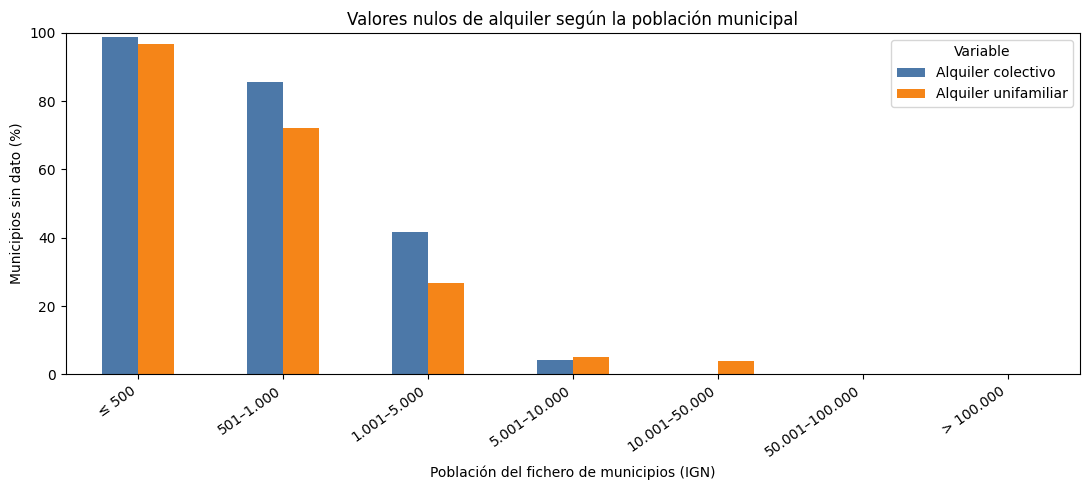

In [28]:
variables_alquiler = {
    'Alquiler colectivo': 'alquiler_precio_colectiva_mediana',
    'Alquiler unifamiliar': 'alquiler_precio_unifamiliar_mediana',
}
columna_poblacion = 'poblacion_ign'

resumen_poblacion_nulos = []
for fuente, columna in variables_alquiler.items():
    for tiene_dato, grupo in df.groupby(df[columna].notna()):
        poblacion = grupo[columna_poblacion].dropna()
        resumen_poblacion_nulos.append({
            'variable': fuente,
            'situacion': 'Con dato' if tiene_dato else 'Sin dato',
            'municipios': len(grupo),
            'poblacion_mediana': poblacion.median(),
            'poblacion_p25': poblacion.quantile(0.25),
            'poblacion_p75': poblacion.quantile(0.75),
            'poblacion_media': poblacion.mean(),
        })

resumen_poblacion_nulos = pd.DataFrame(resumen_poblacion_nulos)
display(resumen_poblacion_nulos.round(1))

limites_poblacion = [-np.inf, 500, 1_000, 5_000, 10_000, 50_000, 100_000, np.inf]
etiquetas_poblacion = [
    '≤ 500', '501–1.000', '1.001–5.000', '5.001–10.000',
    '10.001–50.000', '50.001–100.000', '> 100.000',
]
tramo_poblacion = pd.cut(
    df[columna_poblacion],
    bins=limites_poblacion,
    labels=etiquetas_poblacion,
    include_lowest=True,
)

nulos_por_poblacion = pd.DataFrame({'tramo_poblacion': tramo_poblacion})
for fuente, columna in variables_alquiler.items():
    nulos_por_poblacion[fuente] = df[columna].isna()

nulos_por_poblacion = (
    nulos_por_poblacion
    .groupby('tramo_poblacion', observed=False)
    .agg(
        municipios=('tramo_poblacion', 'size'),
        **{f'{fuente}_nulos_pct': (fuente, lambda serie: serie.mean() * 100)
           for fuente in variables_alquiler}
    )
    .reset_index()
)
display(nulos_por_poblacion.round(2))

columnas_nulos = [f'{fuente}_nulos_pct' for fuente in variables_alquiler]
ax = nulos_por_poblacion.set_index('tramo_poblacion')[columnas_nulos].plot.bar(
    figsize=(11, 5),
    color=['#4C78A8', '#F58518'],
)
ax.set_title('Valores nulos de alquiler según la población municipal')
ax.set_xlabel('Población del fichero de municipios (IGN)')
ax.set_ylabel('Municipios sin dato (%)')
ax.set_ylim(0, 100)
ax.legend(['Alquiler colectivo', 'Alquiler unifamiliar'], title='Variable')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

### Relación entre los nulos de viviendas del INE y la población

Se estudia si la ausencia de información del censo de viviendas se concentra en los municipios con menor `poblacion_ign`.

,variable,situacion,municipios,poblacion_mediana,poblacion_p25,poblacion_p75,poblacion_media
0,Viviendas totales,Sin dato,4993,200.0,91.0,432.0,292.3
1,Viviendas totales,Con dato,3139,3809.0,1851.5,9920.5,15023.9
2,Viviendas vacías,Sin dato,4993,200.0,91.0,432.0,292.3
3,Viviendas vacías,Con dato,3139,3809.0,1851.5,9920.5,15023.9
4,Viviendas de uso esporádico,Sin dato,4993,200.0,91.0,432.0,292.3
5,Viviendas de uso esporádico,Con dato,3139,3809.0,1851.5,9920.5,15023.9
6,Porcentaje de viviendas vacías,Sin dato,4993,200.0,91.0,432.0,292.3
7,Porcentaje de viviendas vacías,Con dato,3139,3809.0,1851.5,9920.5,15023.9
8,Porcentaje de uso esporádico,Sin dato,4993,200.0,91.0,432.0,292.3
9,Porcentaje de uso esporádico,Con dato,3139,3809.0,1851.5,9920.5,15023.9


,tramo_poblacion,municipios,Viviendas totales_nulos_pct,Viviendas vacías_nulos_pct,Viviendas de uso esporádico_nulos_pct,Porcentaje de viviendas vacías_nulos_pct,Porcentaje de uso esporádico_nulos_pct
0,≤ 500,3978,100.00,100.00,100.00,100.00,100.00
1,501–1.000,1004,98.01,98.01,98.01,98.01,98.01
2,1.001–5.000,1827,1.70,1.70,1.70,1.70,1.70
3,5.001–10.000,543,0.00,0.00,0.00,0.00,0.00
4,10.001–50.000,628,0.00,0.00,0.00,0.00,0.00
5,50.001–100.000,87,0.00,0.00,0.00,0.00,0.00
6,> 100.000,65,0.00,0.00,0.00,0.00,0.00


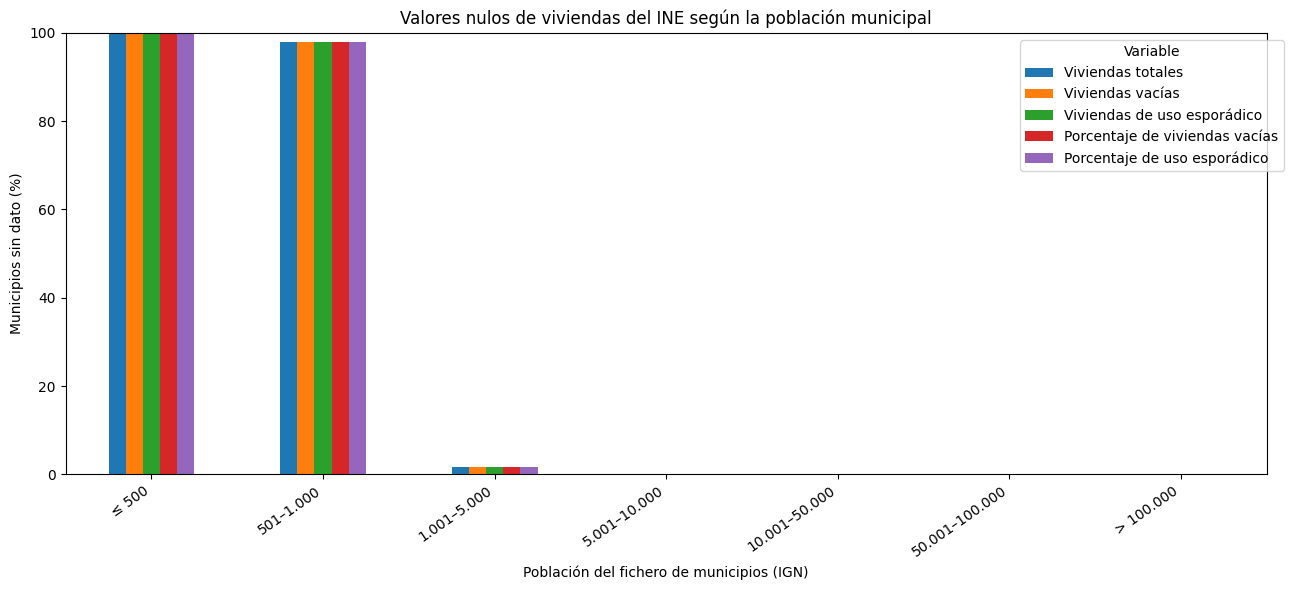

In [29]:
variables_viviendas_ine = {
    'Viviendas totales': 'viviendas_totales',
    'Viviendas vacías': 'viviendas_vacias',
    'Viviendas de uso esporádico': 'viviendas_uso_esporadico',
    'Porcentaje de viviendas vacías': 'porcentaje_viviendas_vacias',
    'Porcentaje de uso esporádico': 'porcentaje_viviendas_uso_esporadico',
}
columna_poblacion = 'poblacion_ign'

resumen_poblacion_nulos_viviendas = []
for variable, columna in variables_viviendas_ine.items():
    for tiene_dato, grupo in df.groupby(df[columna].notna()):
        poblacion = grupo[columna_poblacion].dropna()
        resumen_poblacion_nulos_viviendas.append({
            'variable': variable,
            'situacion': 'Con dato' if tiene_dato else 'Sin dato',
            'municipios': len(grupo),
            'poblacion_mediana': poblacion.median(),
            'poblacion_p25': poblacion.quantile(0.25),
            'poblacion_p75': poblacion.quantile(0.75),
            'poblacion_media': poblacion.mean(),
        })

resumen_poblacion_nulos_viviendas = pd.DataFrame(
    resumen_poblacion_nulos_viviendas
)
display(resumen_poblacion_nulos_viviendas.round(1))

limites_poblacion_viviendas = [
    -np.inf, 500, 1_000, 5_000, 10_000, 50_000, 100_000, np.inf
]
etiquetas_poblacion_viviendas = [
    '≤ 500', '501–1.000', '1.001–5.000', '5.001–10.000',
    '10.001–50.000', '50.001–100.000', '> 100.000',
]
tramo_poblacion_viviendas = pd.cut(
    df[columna_poblacion],
    bins=limites_poblacion_viviendas,
    labels=etiquetas_poblacion_viviendas,
    include_lowest=True,
)

nulos_viviendas_por_poblacion = pd.DataFrame({
    'tramo_poblacion': tramo_poblacion_viviendas,
})
for variable, columna in variables_viviendas_ine.items():
    nulos_viviendas_por_poblacion[variable] = df[columna].isna()

nulos_viviendas_por_poblacion = (
    nulos_viviendas_por_poblacion
    .groupby('tramo_poblacion', observed=False)
    .agg(
        municipios=('tramo_poblacion', 'size'),
        **{f'{variable}_nulos_pct': (
               variable, lambda serie: serie.mean() * 100
           ) for variable in variables_viviendas_ine}
    )
    .reset_index()
)
display(nulos_viviendas_por_poblacion.round(2))

columnas_nulos_viviendas = [
    f'{variable}_nulos_pct' for variable in variables_viviendas_ine
]
ax = nulos_viviendas_por_poblacion.set_index('tramo_poblacion')[
    columnas_nulos_viviendas
].plot.bar(figsize=(13, 6))
ax.set_title('Valores nulos de viviendas del INE según la población municipal')
ax.set_xlabel('Población del fichero de municipios (IGN)')
ax.set_ylabel('Municipios sin dato (%)')
ax.set_ylim(0, 100)
ax.legend(list(variables_viviendas_ine), title='Variable', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## Periodos y estadísticos descriptivos

In [30]:
columnas_periodo = [c for c in df.columns if c.startswith('anio') or c.startswith('periodo')]
for columna in columnas_periodo:
    print(f'\n{columna}')
    display(df[columna].value_counts(dropna=False).sort_index().to_frame('municipios'))

descripcion = df.select_dtypes(include=np.number).describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
descripcion.to_csv(REPORTS_DIR / 'eda_descriptivos.csv', encoding='utf-8')
display(descripcion)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
poblacion_ign,8132.0,5978.811485,49363.916442,2.0,19.0,41.0,153.0,529.0,2444.25,20704.8,88727.75,3422416.0
superficie_km2,8132.0,62.071045,92.006647,0.01,2.8224,6.961,18.4175,34.865,68.8925,201.8005,436.9755,1750.23
densidad_poblacion_hab_km2,8132.0,184.693416,935.505458,0.22,0.7231,1.4655,4.5975,13.385,57.0425,669.7715,3590.9617,23400.0
longitud,8132.0,-3.107776,3.026851,-18.010939,-13.737196,-7.138478,-5.122576,-3.233311,-1.130048,2.088156,3.010784,4.290737
latitud,8132.0,40.725184,2.12196,27.709038,28.952294,37.187946,39.85821,41.184868,42.133411,43.129498,43.41147,43.740351
inmuebles_urbanos,7606.0,5285.732448,35876.524046,23.0,91.05,155.0,366.0,857.5,2681.5,18297.5,71612.4,2284259.0
valor_catastral_total_eur,7606.0,319687614.132204,3920752439.972347,285959.14,977118.5775,1971236.44,6659403.53,22855566.245,102964944.6625,1010892537.09,4893058048.22698,299480127569.289978
valor_catastral_suelo_eur,7606.0,157974101.259816,2655543333.567971,22230.24,95903.9285,233944.2075,1154868.3225,5567086.23,32466377.7775,436252630.135,2432199539.900494,209723205683.01001
superficie_urbana_m2,7606.0,1381312.813831,4583473.399893,5463.0,16287.85,30683.25,101625.0,287331.5,1060934.0,6111827.0,15741864.9,237000575.0
parcelas_urbanas,7606.0,1855.685643,3836.501858,20.0,89.0,149.0,343.25,753.5,1932.0,6890.75,14244.8,136259.0


## Asimetría

,asimetria
valor_catastral_suelo_eur,68.511422
valor_catastral_suelo_eur_catastro_2021,68.499578
valor_catastral_total_eur_catastro_2021,62.963171
valor_catastral_total_eur,62.928071
valor_catastral_residencial_eur_catastro_2021,61.592766
valor_catastral_residencial_eur,61.526758
saldo_exterior,53.551164
saldo_interior,-51.898673
saldo_total,49.871917
poblacion_2025,48.2637


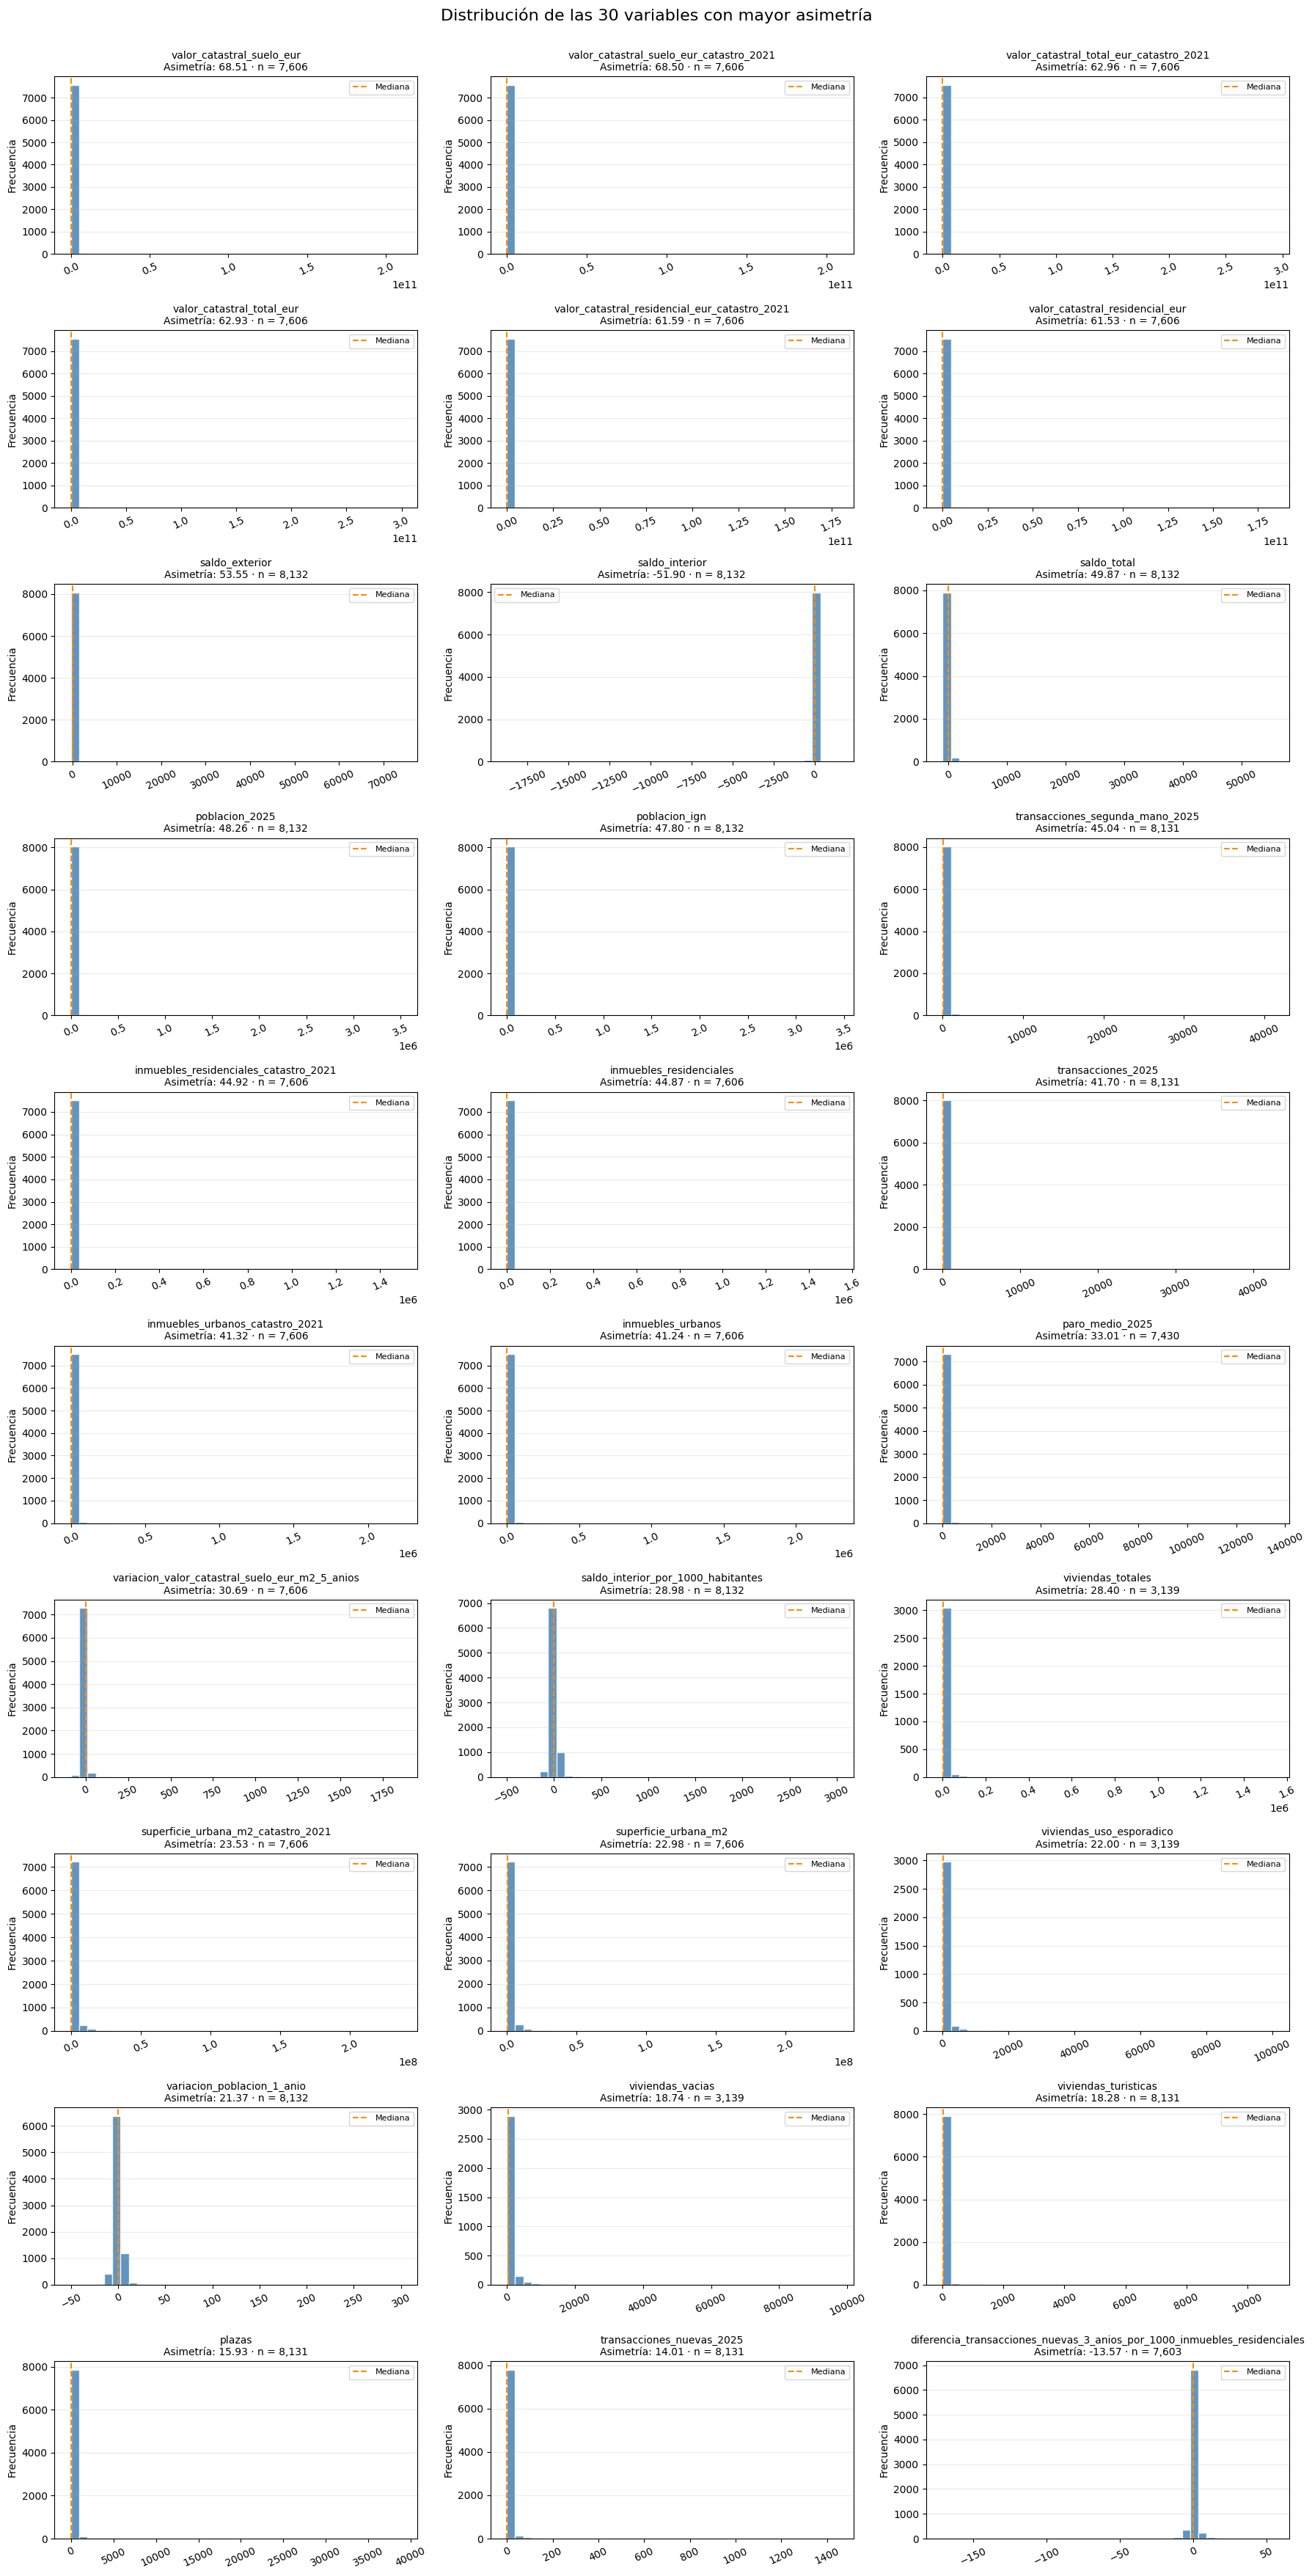

In [36]:
numericas = df.select_dtypes(include=np.number)
asimetria = numericas.skew().sort_values(key=abs, ascending=False).to_frame('asimetria')
# Se muestran las 30 variables con mayor asimetría (positiva o negativa)
display(asimetria.head(30))

variables_asimetricas = asimetria.head(30).index

n_columnas = 3
n_filas = int(np.ceil(len(variables_asimetricas) / n_columnas))

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(18, n_filas * 3.5),
)

axes = np.asarray(axes).flatten()

for ax, variable in zip(axes, variables_asimetricas):
    valores = (
        pd.to_numeric(df[variable], errors='coerce')
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype(float)
    )

    ax.hist(
        valores,
        bins=40,
        color='steelblue',
        edgecolor='white',
        alpha=0.85,
    )

    ax.axvline(
        valores.median(),
        color='darkorange',
        linestyle='--',
        linewidth=1.5,
        label='Mediana',
    )

    ax.set_title(
        f'{variable}\n'
        f'Asimetría: {asimetria.loc[variable, "asimetria"]:.2f} · '
        f'n = {len(valores):,}',
        fontsize=10,
    )
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.25)

# Se eliminan los ejes sobrantes si cambia el número de variables.
for ax in axes[len(variables_asimetricas):]:
    fig.delaxes(ax)

fig.suptitle(
    'Distribución de las 30 variables con mayor asimetría',
    fontsize=16,
    y=1.002,
)

fig.tight_layout()
plt.show()


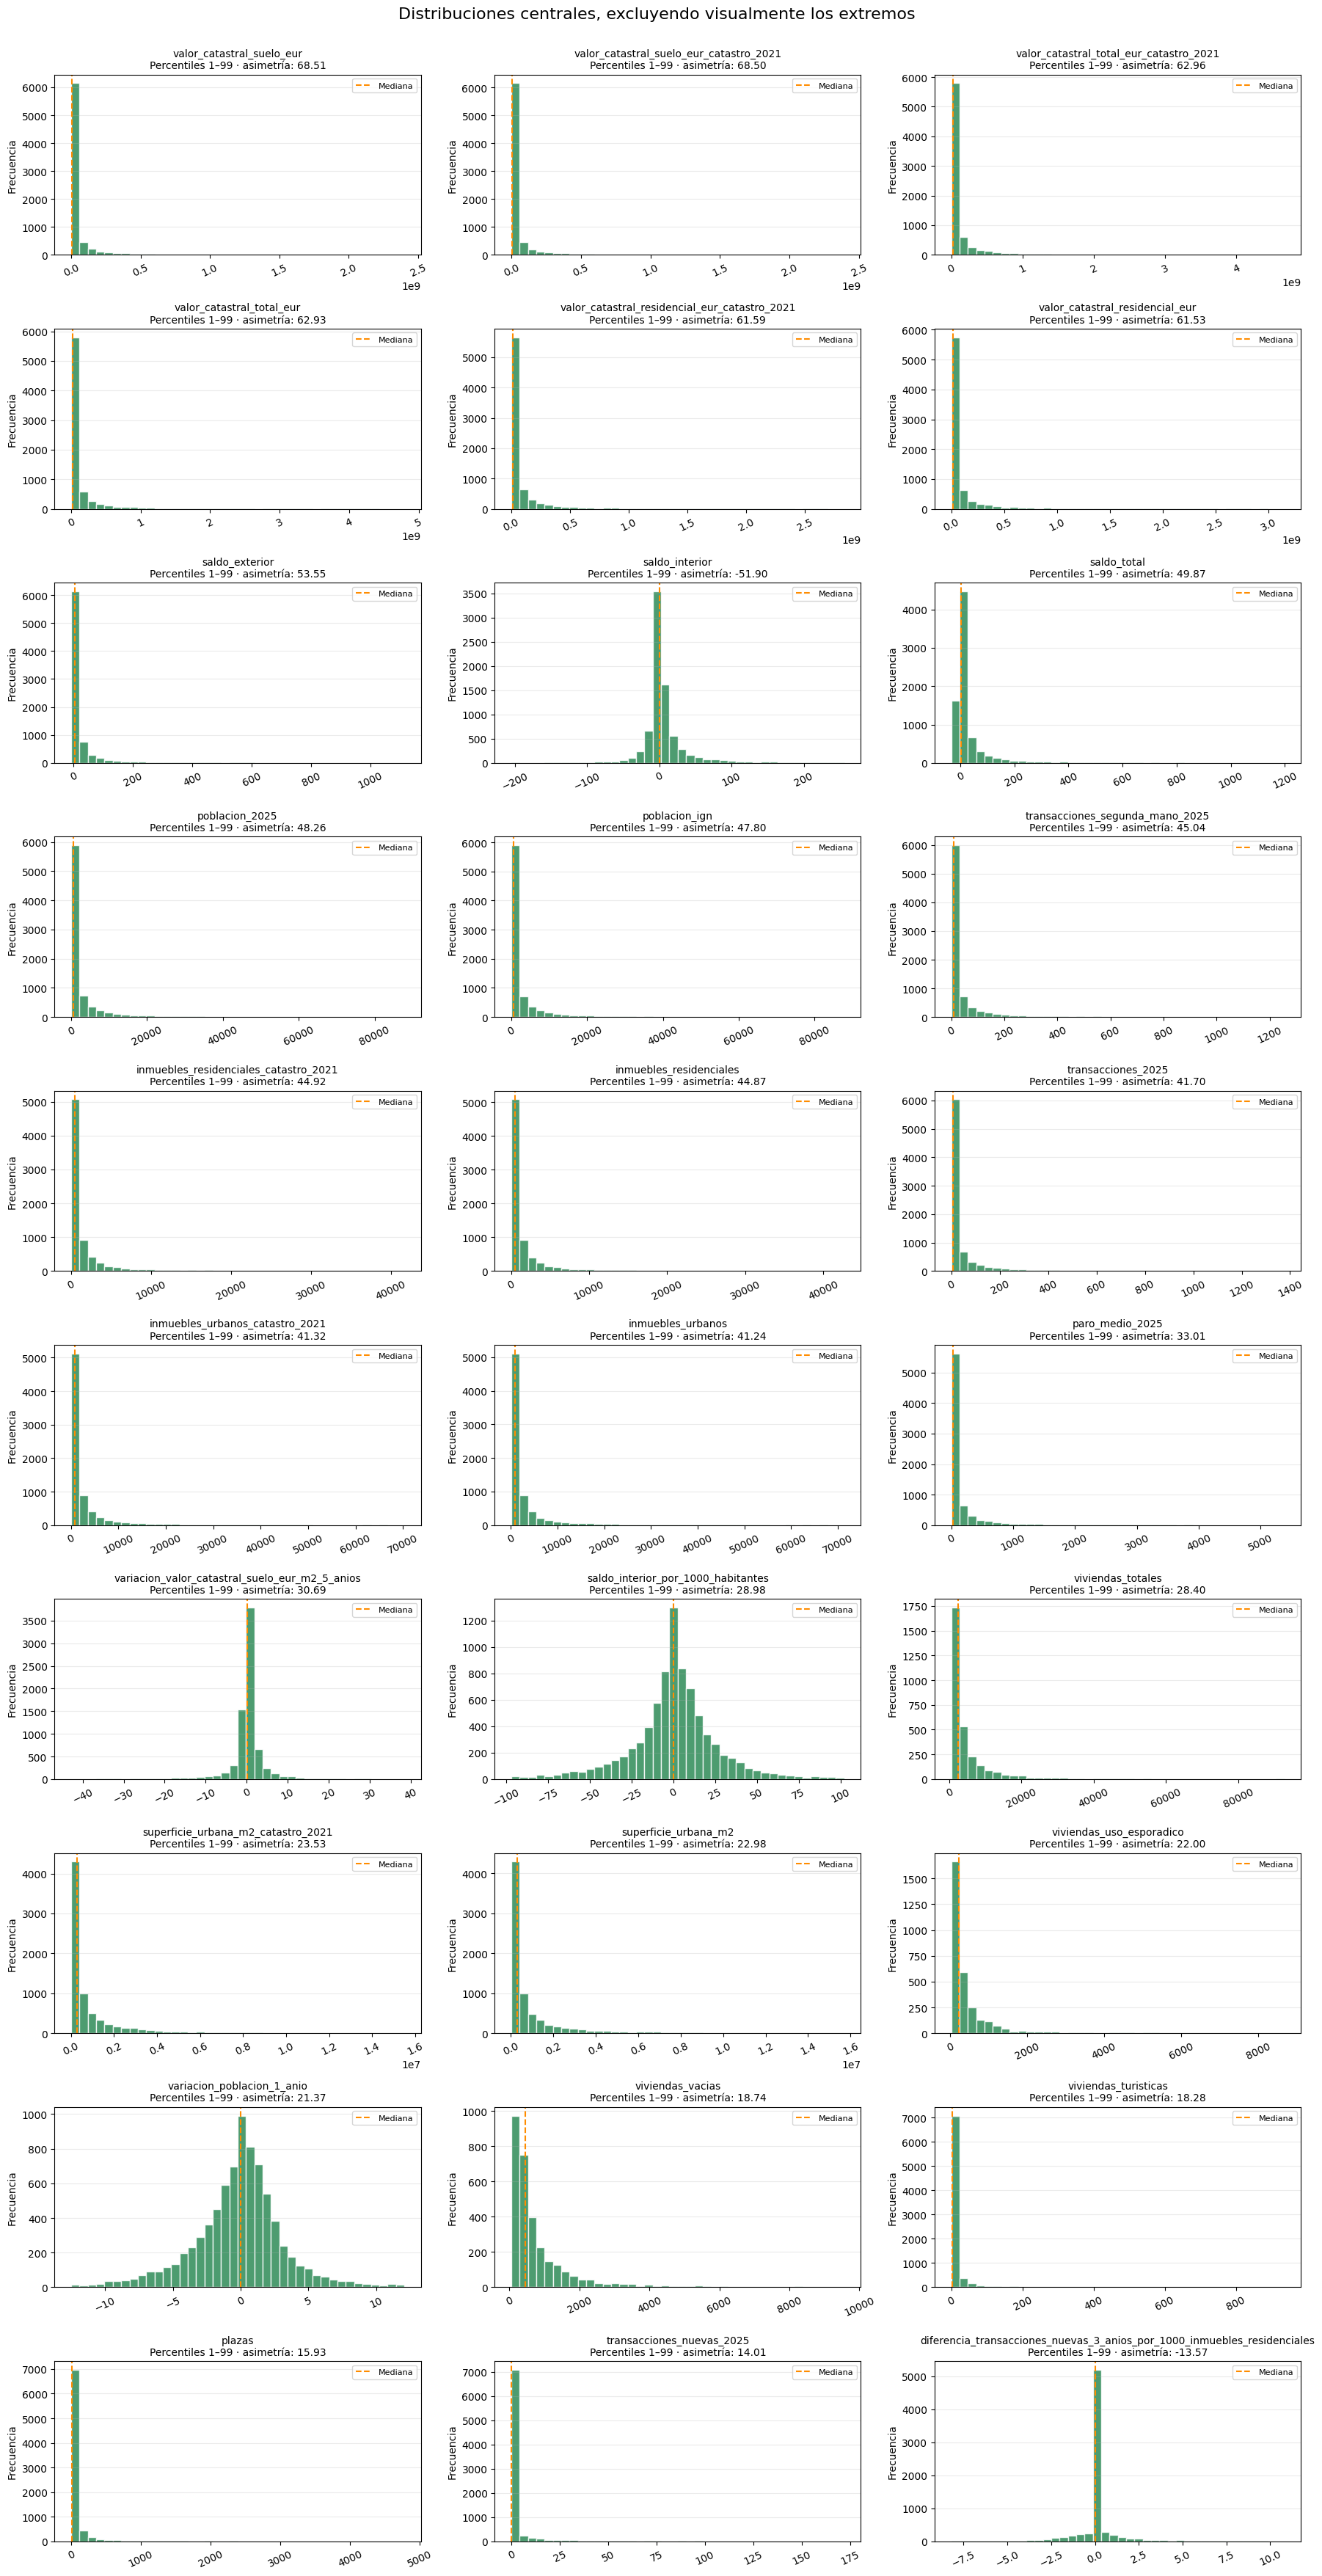

In [38]:
# Histogramas de las 30 variables con mayor asimetría, excluyendo visualmente los extremos (percentiles 1 y 99)

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(18, n_filas * 3.5),
)

axes = np.asarray(axes).flatten()

for ax, variable in zip(axes, variables_asimetricas):
    valores = (
        pd.to_numeric(df[variable], errors='coerce')
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype(float)
    )

    limite_inferior = valores.quantile(0.01)
    limite_superior = valores.quantile(0.99)
    valores_centrales = valores.between(
        limite_inferior,
        limite_superior,
        inclusive='both',
    )

    ax.hist(
        valores[valores_centrales],
        bins=40,
        color='seagreen',
        edgecolor='white',
        alpha=0.85,
    )

    ax.axvline(
        valores.median(),
        color='darkorange',
        linestyle='--',
        linewidth=1.5,
        label='Mediana',
    )

    ax.set_title(
        f'{variable}\n'
        f'Percentiles 1–99 · asimetría: '
        f'{asimetria.loc[variable, "asimetria"]:.2f}',
        fontsize=10,
    )
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.25)

for ax in axes[len(variables_asimetricas):]:
    fig.delaxes(ax)

fig.suptitle(
    'Distribuciones centrales, excluyendo visualmente los extremos',
    fontsize=16,
    y=1.002,
)

fig.tight_layout()
plt.show()

### Correlaciones entre variables

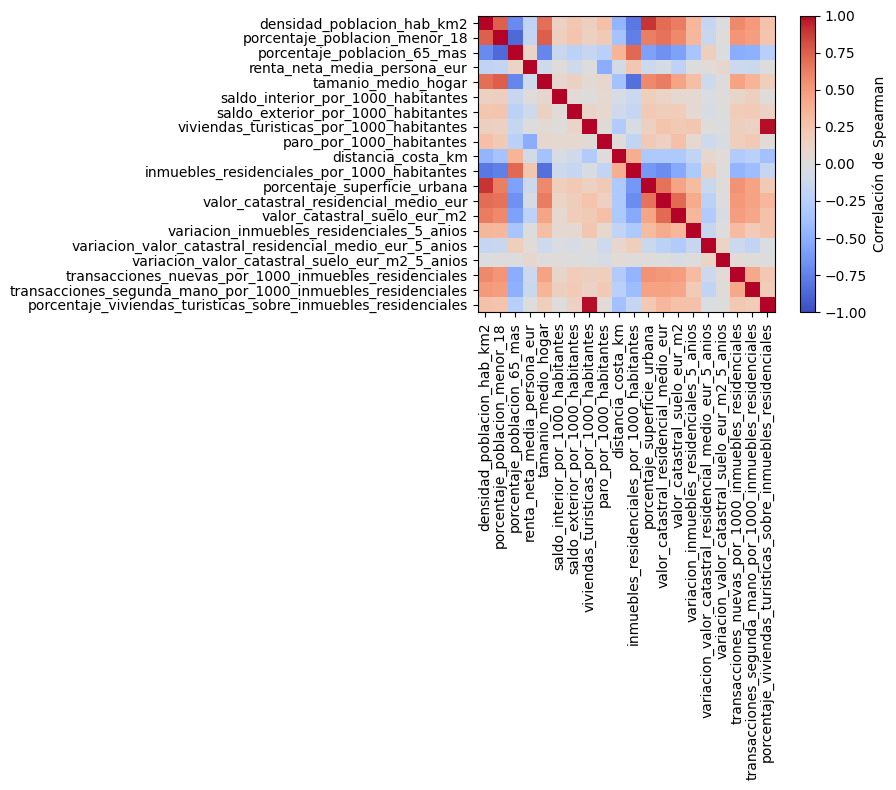

In [34]:
variables_revision = [
    'densidad_poblacion_hab_km2',
    'porcentaje_poblacion_menor_18',
    'porcentaje_poblacion_65_mas',
    'renta_neta_media_persona_eur',
    'tamanio_medio_hogar',
    'saldo_interior_por_1000_habitantes',
    'saldo_exterior_por_1000_habitantes',
    'viviendas_turisticas_por_1000_habitantes',
    'paro_por_1000_habitantes',
    'distancia_costa_km',
    'inmuebles_residenciales_por_1000_habitantes',
    'porcentaje_superficie_urbana',
    'valor_catastral_residencial_medio_eur',
    'valor_catastral_suelo_eur_m2',
    'variacion_inmuebles_residenciales_5_anios',
    'variacion_valor_catastral_residencial_medio_eur_5_anios',
    'variacion_valor_catastral_suelo_eur_m2_5_anios',
    'transacciones_nuevas_por_1000_inmuebles_residenciales',
    'transacciones_segunda_mano_por_1000_inmuebles_residenciales',
    'porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales',
]
corr = df[variables_revision].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(imagen, ax=ax, label='Correlación de Spearman')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'correlaciones_iniciales.png', dpi=160, bbox_inches='tight')
plt.show()